In [1]:
import re
import time
import joblib
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
tr=pd.read_csv("True.csv")

In [3]:
fk=pd.read_csv("Fake.csv")

In [4]:
tr.shape

(21417, 4)

In [5]:
fk.shape

(23481, 4)

In [6]:
tr.columns

Index(['title', 'text', 'subject', 'date'], dtype='str')

In [7]:
tr.isnull().sum()

title      0
text       0
subject    0
date       0
dtype: int64

In [8]:
fk.isnull().sum()

title      0
text       0
subject    0
date       0
dtype: int64

In [9]:
fk["label"]=1

In [10]:
tr["label"]=0

In [11]:
df=pd.concat([tr,fk],ignore_index=True)

In [12]:
df.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",0
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",0
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",0
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",0


In [13]:
df.shape

(44898, 5)

In [14]:
df["label"].value_counts()

label
1    23481
0    21417
Name: count, dtype: int64

In [15]:
df=df.sample(frac=1,random_state=42).reset_index(drop=True)

In [16]:
df["label"].value_counts(normalize=True)

label
1    0.522985
0    0.477015
Name: proportion, dtype: float64

In [17]:
df.duplicated().sum()

np.int64(209)

In [18]:
df.duplicated(subset="title").sum()

np.int64(6169)

In [19]:
df.duplicated(subset="text").sum()

np.int64(6252)

In [20]:
df[df.duplicated(subset="text")]["label"].value_counts()

label
1    6026
0     226
Name: count, dtype: int64

In [21]:
df[df.duplicated(subset="text")]["text"].str.len().describe()

count     6252.000000
mean      2550.837652
std       3267.662264
min          1.000000
25%        871.000000
50%       1836.000000
75%       3179.000000
max      51794.000000
Name: text, dtype: float64

In [22]:
df[df.duplicated(subset="text")]["title"].sample(5)

21798    HYSTERICAL! The Guy Who’s Spent Majority Of Bo...
34988    NOT-IMPARTIAL DEBATE MODERATOR Martha Raddatz ...
39465    JUDGE NAPOLITANO On Bombshell That Intel Isn’t...
20555    BOOM! CUSTOMS AGENTS IGNORE Obama Appointed Ju...
8565     N. KOREA WARNS It Will Strike U.S. Bases In S....
Name: title, dtype: str

In [23]:
cnt=df.groupby("text")["label"].nunique()

In [24]:
(cnt==2).sum()

np.int64(1)

In [25]:
cnt[cnt==2].index

Index([' '], dtype='str', name='text')

In [26]:
length=df["text"].str.strip().str.len()

In [27]:
length.min()

np.int64(0)

In [28]:
(length==0).sum()

np.int64(631)

In [29]:
df[length==0]["label"].value_counts()

label
1    630
0      1
Name: count, dtype: int64

In [30]:
df[length<20]["label"].value_counts()

label
1    671
0      1
Name: count, dtype: int64

In [31]:
df[length<50]["label"].value_counts()

label
1    836
0      1
Name: count, dtype: int64

In [32]:
df[length<100]["label"].value_counts()

label
1    1047
0       1
Name: count, dtype: int64

In [33]:
df[(length>=1) & (length<=99)]["text"].sample(5)


53       Joe Biden was at Miami Dade College speaking w...
21159          https://www.youtube.com/watch?v=n9tfNMQpYWU
44874    Who wrote this garble for granny Clinton? She ...
34080    Here s a first-hand look at the crazy state of...
8561     This isn t the first time Pelosi has lost it i...
Name: text, dtype: str

In [34]:
df[length==0]["title"].sample(5)

33841    Ohio State University Student Says Terrorist A...
31259    SHOW THIS TO YOUR FRIENDS Who Don’t Fully Gras...
30740    CNN’S FAREED ZAKARIA Busts Out a Profanity Fil...
30105    MTV Releases Racist ‘Hey Fellow White Guy’s Vi...
15250    JUDGE JEANINE ON FIRE: “Paul Ryan Needs to Ste...
Name: title, dtype: str

In [35]:
df[length==0]["subject"].value_counts()

subject
politics           408
left-news          150
Government News     72
politicsNews         1
Name: count, dtype: int64

In [36]:
df=df.drop_duplicates(subset="text")

In [37]:
df=df.reset_index(drop=True)

In [38]:
df.shape

(38646, 5)

In [39]:
df["label"].value_counts(normalize=True)

label
0    0.548336
1    0.451664
Name: proportion, dtype: float64

In [40]:
length=df["text"].str.strip().str.len()

In [41]:
df[length<20]["label"].value_counts()

label
1    27
Name: count, dtype: int64

In [42]:
df[length<100]["label"].value_counts()

label
1    305
Name: count, dtype: int64

In [43]:
df=df[length>=100]

In [44]:
df=df.reset_index(drop=True)

In [45]:
df.shape

(38341, 5)

In [46]:
df["label"].value_counts()

label
0    21191
1    17150
Name: count, dtype: int64

In [47]:
df["label"].value_counts(normalize=True)

label
0    0.552698
1    0.447302
Name: proportion, dtype: float64

In [48]:
df["word_count"]=df["text"].str.split().str.len()

In [49]:
(df["word_count"]<10).sum()

np.int64(3)

In [50]:
df=df[df["word_count"]>=10].reset_index(drop=True)

In [51]:
df.shape

(38338, 6)

In [52]:
df["label"].value_counts()

label
0    21191
1    17147
Name: count, dtype: int64

In [53]:
df.groupby("label")["word_count"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,21191.0,384.830919,273.783236,22.0,147.0,359.0,523.0,5172.0
1,17147.0,432.733948,353.924416,11.0,285.0,380.0,506.0,8135.0


In [54]:
(df["word_count"]>1500).groupby(df["label"]).sum()

label
0     34
1    230
Name: word_count, dtype: int64

In [55]:
df["word_count"].idxmax()

15795

In [56]:
df.loc[15795,"text"][:300]

' Funny how secrets travel. I d start to believe, if I were to bleed.    Lyrics written by David Bowie from the album OutsideShawn Helton 21st Century Wire In the days before the US presidential election in November 2016, Wikileaks revealed a new string of emails connected to Hillary Clinton s 2016 c'

In [57]:
df.loc[15795,"title"]

'MEDIA TRIPWIRE? Ping Pong Pizza Conspiracy Propels Internet Censorship Amid ‘Fake News’ Witch-Hunt'

In [58]:
df[df["label"]==0]["word_count"].idxmax()

np.int64(22537)

In [59]:
df.loc[22537,"text"][:300]

'(Reuters) - U.S. Environmental Protection Agency Administrator Scott Pruitt gave Reuters a wide-ranging interview on Monday at his office in Washington, discussing issues from climate science to automobile emissions.  The following is a full transcript of the interview: REUTERS: You have said the EP'

In [60]:
df.loc[22537,"title"]

'Transcript of Reuters interview with EPA Administrator Scott Pruitt'

In [61]:
pd.crosstab(df["subject"],df["label"])

label,0,1
subject,,
Government News,0,867
Middle-east,0,387
News,0,9050
US_News,0,396
left-news,0,2344
politics,0,4103
politicsNews,11209,0
worldnews,9982,0


In [62]:
df["text"].str.contains("Reuters").groupby(df["label"]).sum()

label
0    21154
1      215
Name: text, dtype: int64

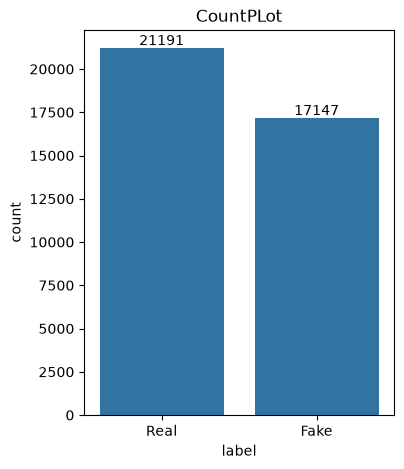

In [63]:
plt.figure(figsize=(4,5))
s=sns.countplot(x="label",data=df)
s.bar_label(s.containers[0])#Exact no on top of graphs
plt.title("CountPLot")
plt.xticks([0,1],["Real","Fake"])
plt.show()


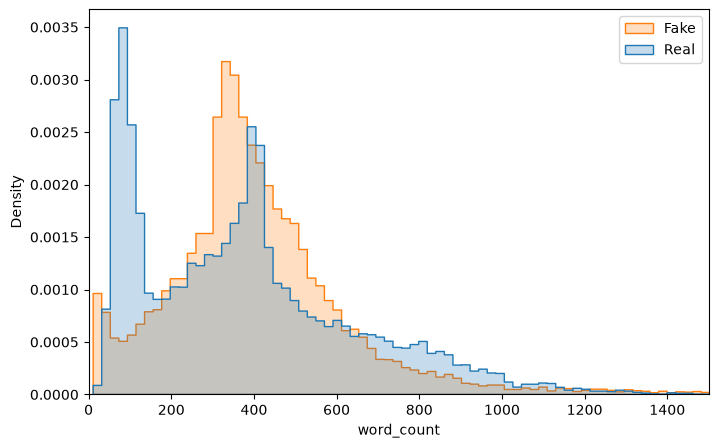

In [64]:
plt.figure(figsize=(8,5))
sns.histplot(x="word_count",data=df,hue="label",stat="density",common_norm=False,element="step")
plt.legend(["Fake","Real"])
plt.xlim(0,1500)
plt.show()

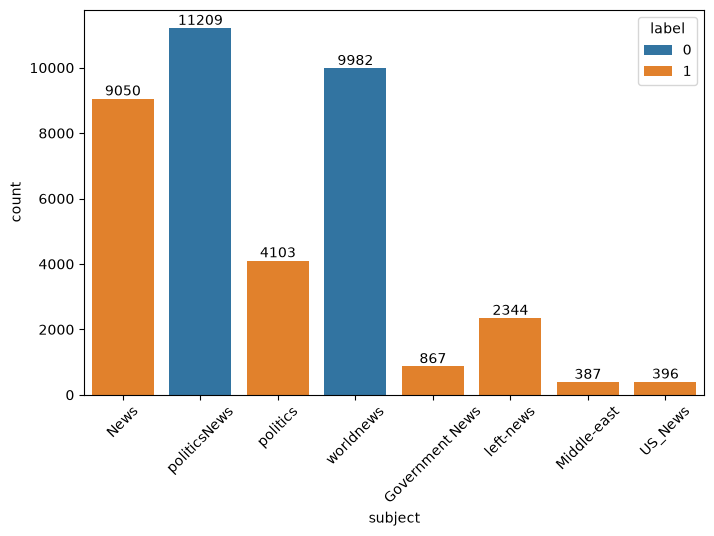

In [65]:
plt.figure(figsize=(8,5))
x=sns.countplot(x="subject",data=df,hue="label")
plt.xticks(rotation=45)
for i in range(2):
    x.bar_label(x.containers[i])

plt.show()


In [66]:
real_df=df[df["label"]==0]
fake_df=df[df["label"]==1]

In [67]:
cv_real = CountVectorizer(max_features=15)
X_real = cv_real.fit_transform(real_df["text"])
real_top_stop = pd.DataFrame(X_real.toarray(), columns=cv_real.get_feature_names_out()).sum().sort_values(ascending=False)
real_top_stop

the      476245
to       242636
of       202728
and      179769
in       179264
on       107150
said      97814
that      87182
for       78908
is        54797
trump     54073
with      53844
he        53674
it        48907
by        47366
dtype: int64

In [68]:
cv_fake = CountVectorizer(max_features=15)
X_fake = cv_fake.fit_transform(fake_df["text"])
fake_top_stop = pd.DataFrame(X_fake.toarray(), columns=cv_fake.get_feature_names_out()).sum().sort_values(ascending=False)
fake_top_stop

the      395167
to       218261
of       172252
and      168228
in       124534
that     117875
is        86134
for       69613
trump     68041
it        65180
he        64519
on        62049
was       49556
with      47335
his       46911
dtype: int64

In [69]:
cv_real2 = CountVectorizer(max_features=15, stop_words="english")
X_real2 = cv_real2.fit_transform(real_df["text"])
real_top = pd.DataFrame(X_real2.toarray(), columns=cv_real2.get_feature_names_out()).sum().sort_values(ascending=False)
real_top

said          97814
trump         54073
reuters       28652
president     27855
state         20781
government    18550
new           16735
house         16462
states        16411
republican    16135
united        15360
people        15076
year          14583
told          14061
washington    12884
dtype: int64

In [70]:
cv_fake2 = CountVectorizer(max_features=15, stop_words="english")
X_fake2 = cv_fake2.fit_transform(fake_df["text"])
fake_top = pd.DataFrame(X_fake2.toarray(), columns=cv_fake2.get_feature_names_out()).sum().sort_values(ascending=False)
fake_top

trump        68041
said         24798
people       21177
president    20787
just         16723
donald       15277
like         14350
clinton      13515
obama        13362
time         10700
new          10394
white        10306
news         10206
hillary       9924
state         9488
dtype: int64

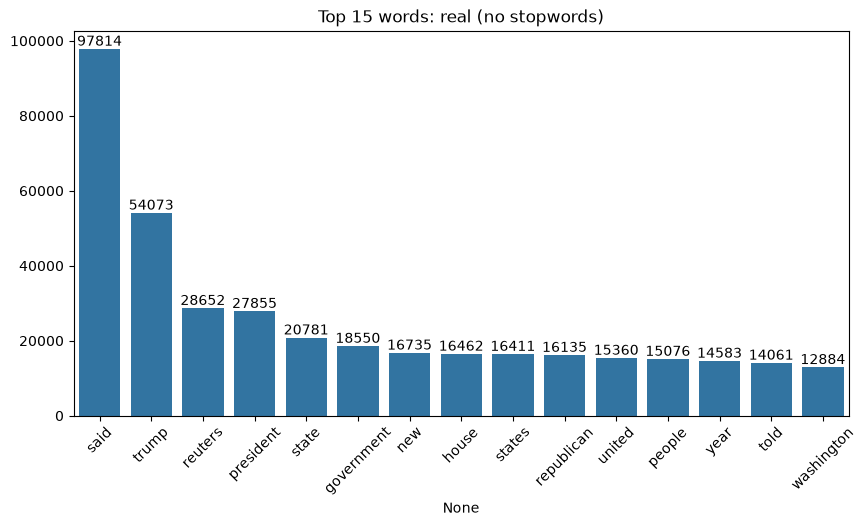

In [71]:
plt.figure(figsize=(10,5))
ax=sns.barplot(x=real_top.index,y=real_top.values)
plt.title("Top 15 words: real (no stopwords)")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=45)
plt.show()

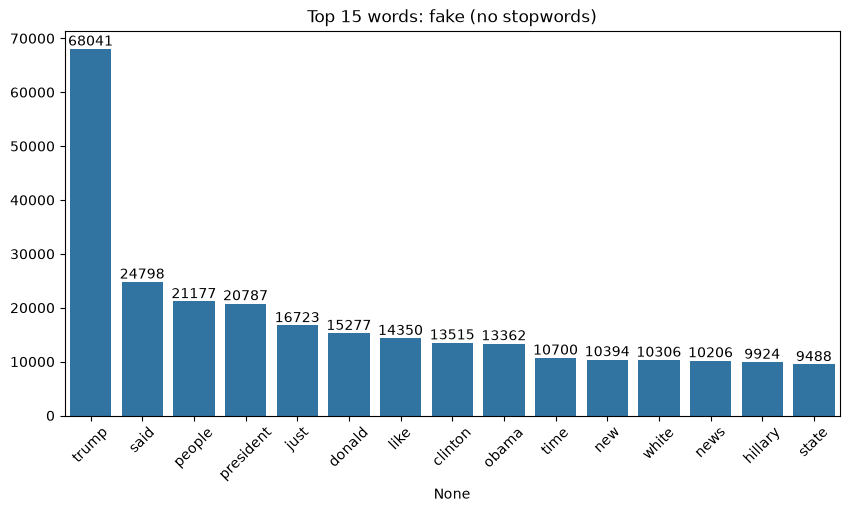

In [72]:
plt.figure(figsize=(10,5))
ax=sns.barplot(x=fake_top.index,y=fake_top.values)
plt.title("Top 15 words: fake (no stopwords)")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=45)
plt.show()

In [73]:
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Adarsh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [74]:
stop_words = set(stopwords.words("english"))

In [75]:
print(len(stop_words))
print("s" in stop_words)

198
True


In [76]:
sample = "BREAKING: Trump s White House said, 'We WILL win!!' https://t.co/abc 100% sure"


In [77]:
def clean_text(text):
    step1=text.lower()
    
    step2=re.sub(r"http\S+", " ", step1)
    
    step3 = re.sub(r"[^a-z\s]", " ", step2)
    
    words=step3.split()
    
    kept = [w for w in words if w not in stop_words]
    
    return " ".join(kept)

In [78]:
st =time.time()

test=df["text"].head(500).apply(clean_text)

print(time.time()-st ,"seconds")

0.1174013614654541 seconds


In [79]:
df["clean"]=df["text"].apply(clean_text)

In [80]:
df.shape

(38338, 7)

In [81]:
df[["text","clean"]].head()

,text,clean
0,"Donald Trump s White House is in chaos, and th...",donald trump white house chaos trying cover ru...
1,Now that Donald Trump is the presumptive GOP n...,donald trump presumptive gop nominee time reme...
2,Mike Pence is a huge homophobe. He supports ex...,mike pence huge homophobe supports ex gay conv...
3,SAN FRANCISCO (Reuters) - California Attorney ...,san francisco reuters california attorney gene...
4,Twisted reasoning is all that comes from Pelos...,twisted reasoning comes pelosi days especially...


In [82]:
(df["clean"].str.len()==0).sum()

np.int64(0)

In [83]:
df.to_csv("fully_cleaned.csv",index=False)

In [84]:
finaldf=pd.read_csv("fully_cleaned.csv")

In [85]:
X=finaldf["clean"]

In [86]:
Y=finaldf["label"]

In [87]:
from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,Y_test=train_test_split(
    X,
    Y,
    test_size=0.2,
    stratify=Y,
    random_state=42
)

In [88]:
X_train.shape

(30670,)

In [89]:
X_test.shape

(7668,)

In [90]:
Y_train.value_counts()

label
0    16953
1    13717
Name: count, dtype: int64

In [91]:
Y_test.value_counts()

label
0    4238
1    3430
Name: count, dtype: int64

In [92]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf=TfidfVectorizer(max_features=5000,min_df=5)

X_train_tf=tf.fit_transform(X_train)

X_test_tf=tf.transform(X_test)

from sklearn.linear_model import LogisticRegression

md=LogisticRegression(max_iter=1000)

md.fit(X_train_tf,Y_train)

Y_pred=md.predict(X_test_tf)
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

accuracy_score(Y_test,Y_pred)





0.9850026082420449

In [93]:
confusion_matrix(Y_test,Y_pred)

array([[4204,   34],
       [  81, 3349]])

In [94]:

print(classification_report(Y_test,Y_pred))


              precision    recall  f1-score   support

           0       0.98      0.99      0.99      4238
           1       0.99      0.98      0.98      3430

    accuracy                           0.99      7668
   macro avg       0.99      0.98      0.98      7668
weighted avg       0.99      0.99      0.98      7668



In [95]:
weights = pd.Series(md.coef_[0], index=tf.get_feature_names_out()).sort_values()
print(weights.head(15))   # words pushing toward real
print(weights.tail(15))   # words pushing toward fake

reuters        -22.688880
said           -16.185997
washington      -6.408865
tuesday         -5.032619
wednesday       -4.953257
republican      -4.307627
thursday        -4.278119
friday          -4.161967
nov             -3.843236
monday          -3.754526
presidential    -3.553758
minister        -3.365818
reporters       -3.261791
edt             -3.189419
comment         -2.981538
dtype: float64
wire         3.661262
like         3.716797
pic          3.957668
watch        4.080817
hillary      4.251713
com          4.317473
getty        4.331507
mr           4.354205
even         4.415897
gop          5.318331
image        5.781798
featured     5.800398
us           6.065181
read         6.212379
via         11.025544
dtype: float64


In [96]:
def remove_words(text, words_to_remove):
    return " ".join(w for w in text.split() if w not in words_to_remove)

In [97]:
leak_a = ["reuters", "washington"]

X_train_a = X_train.apply(remove_words, words_to_remove=leak_a)
X_test_a = X_test.apply(remove_words, words_to_remove=leak_a)

tf_a = TfidfVectorizer(max_features=5000, min_df=5)
X_train_a_tf = tf_a.fit_transform(X_train_a)
X_test_a_tf = tf_a.transform(X_test_a)

md_a = LogisticRegression(max_iter=1000)
md_a.fit(X_train_a_tf, Y_train)
print(accuracy_score(Y_test, md_a.predict(X_test_a_tf)))

0.9783515910276473


In [98]:
leak_b = leak_a + ["monday", "tuesday", "wednesday", "thursday", "friday", "nov", "edt",
                   "via", "read", "featured", "image", "pic", "getty", "com", "wire", "watch"]

X_train_b = X_train.apply(remove_words, words_to_remove=leak_b)
X_test_b = X_test.apply(remove_words, words_to_remove=leak_b)

tf_b = TfidfVectorizer(max_features=5000, min_df=5)
X_train_b_tf = tf_b.fit_transform(X_train_b)
X_test_b_tf = tf_b.transform(X_test_b)

md_b = LogisticRegression(max_iter=1000)
md_b.fit(X_train_b_tf, Y_train)
print(accuracy_score(Y_test, md_b.predict(X_test_b_tf)))

0.9694835680751174


In [99]:
leak_final = leak_b + ["moscow", "london", "ly", "images", "video", "daily", "us", "sen", "rep",
                       "mr", "reporters", "spokesman", "comment", "said"]
print(len(leak_final), "words removed")

X_train_f = X_train.apply(remove_words, words_to_remove=leak_final)
X_test_f = X_test.apply(remove_words, words_to_remove=leak_final)

tf_final = TfidfVectorizer(max_features=5000, min_df=5)
X_train_f_tf = tf_final.fit_transform(X_train_f)
X_test_f_tf = tf_final.transform(X_test_f)

md_final = LogisticRegression(max_iter=1000)
md_final.fit(X_train_f_tf, Y_train)
print(accuracy_score(Y_test, md_final.predict(X_test_f_tf)))

32 words removed
0.9629629629629629


In [100]:
joblib.dump(md_final, "model.joblib")
joblib.dump(tf_final, "vectorizer.joblib")
joblib.dump(leak_final, "leak_words.joblib")

['leak_words.joblib']